# 02 - Analisis exploratorio de UNSW-NB15

Explora el dataset limpio generado por `python -m src.preprocess --dataset unsw_nb15`: resumen de limpieza, desbalance de clases, correlacion y distribucion de variables clave por clase.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().resolve()
while not (ROOT / 'AGENT.md').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import config
from src.data_loader import load_processed, split_features_target

DATASET = config.get_dataset('unsw_nb15')
sns.set_theme(style='whitegrid')
df = load_processed(DATASET.key)
X, y, attack = split_features_target(df)
numeric = X.select_dtypes('number')
print(df.shape)

(153270, 44)


## 1. Resumen de limpieza

In [2]:
report = json.loads(DATASET.cleaning_report_file.read_text(encoding='utf-8'))
steps = pd.Series({
    'Filas crudas': report['rows_raw'],
    'Con inf/NaN (eliminadas)': -report['rows_removed_missing'],
    'Duplicados exactos (eliminados)': -report['rows_removed_duplicates'],
    'Etiquetas conflictivas (eliminadas)': -report['rows_removed_conflicting'],
    'Filas finales': report['rows_final'],
})
print(steps.to_string())
print('\nColumnas constantes eliminadas:', report['constant_columns_dropped'])
print('Variables finales:', report['n_features'])
raw = pd.Series(report['attack_type_counts_raw']); final = pd.Series(report['attack_type_counts_final'])
print(pd.DataFrame({'crudo': raw, 'final': final, 'retenido_%': (final / raw * 100).round(1)}).to_string())

Filas crudas                           257673
Con inf/NaN (eliminadas)                    0
Duplicados exactos (eliminados)       -103575
Etiquetas conflictivas (eliminadas)      -828
Filas finales                          153270

Columnas constantes eliminadas: []
Variables finales: 42
                crudo  final  retenido_%
Analysis         2677    836        31.2
BENIGN          93000  85308        91.7
Backdoor         2329    583        25.0
DoS             16353   4190        25.6
Exploits        44525  25806        58.0
Fuzzers         24246  18982        78.3
Generic         58871   7305        12.4
Reconnaissance  13987   8646        61.8
Shellcode        1511   1450        96.0
Worms             174    164        94.3


## 2. Desbalance de clases

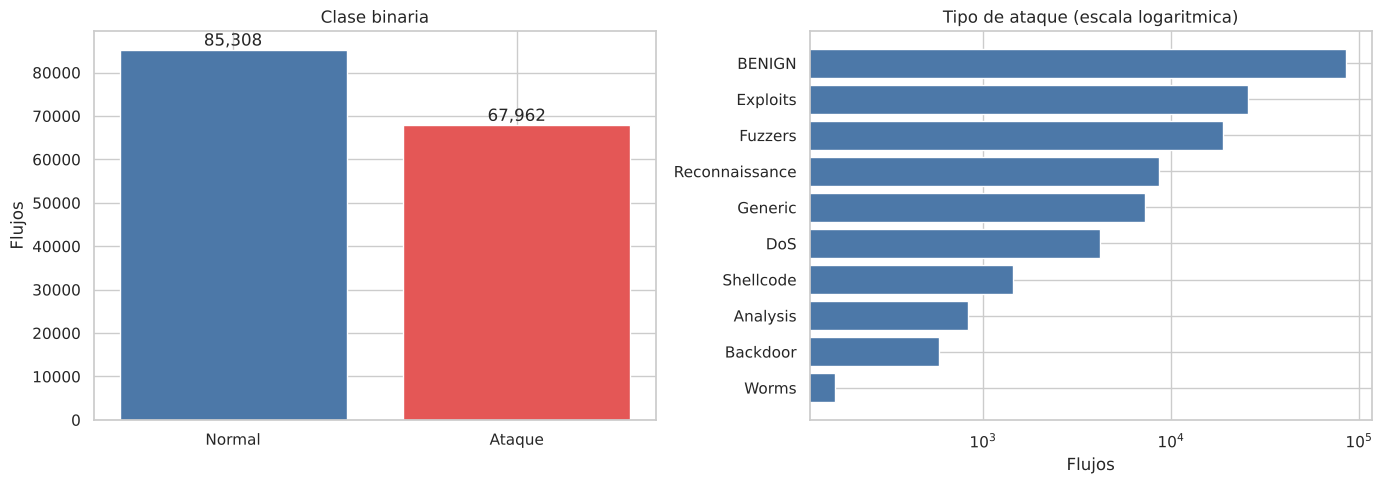

attack_type
BENIGN            55.6586
Exploits          16.8370
Fuzzers           12.3847
Reconnaissance     5.6410
Generic            4.7661
DoS                2.7337
Shellcode          0.9460
Analysis           0.5454
Backdoor           0.3804
Worms              0.1070


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
binary = y.map({0: 'Normal', 1: 'Ataque'}).value_counts()
axes[0].bar(binary.index, binary.values, color=['#4C78A8', '#E45756'])
axes[0].set_title('Clase binaria')
axes[0].set_ylabel('Flujos')
for i, v in enumerate(binary.values):
    axes[0].text(i, v, f'{v:,}', ha='center', va='bottom')
counts = attack.value_counts()
axes[1].barh(counts.index[::-1], counts.values[::-1], color='#4C78A8')
axes[1].set_xscale('log')
axes[1].set_title('Tipo de ataque (escala logaritmica)')
axes[1].set_xlabel('Flujos')
plt.tight_layout()
plt.show()
print((counts / len(df) * 100).round(4).to_string())

## 3. Correlacion entre variables

Pares con |r| > 0.95: 8 de 1521
is_ftp_login  ct_ftp_cmd         0.9990
sbytes        sloss              0.9969
dbytes        dloss              0.9968
dpkts         dloss              0.9791
spkts         sloss              0.9744
dpkts         dbytes             0.9736
swin          dwin               0.9702
spkts         sbytes             0.9669
sinpkt        is_sm_ips_ports    0.9384
tcprtt        synack             0.9355

Variables que el filtro de correlacion descartaria: 6


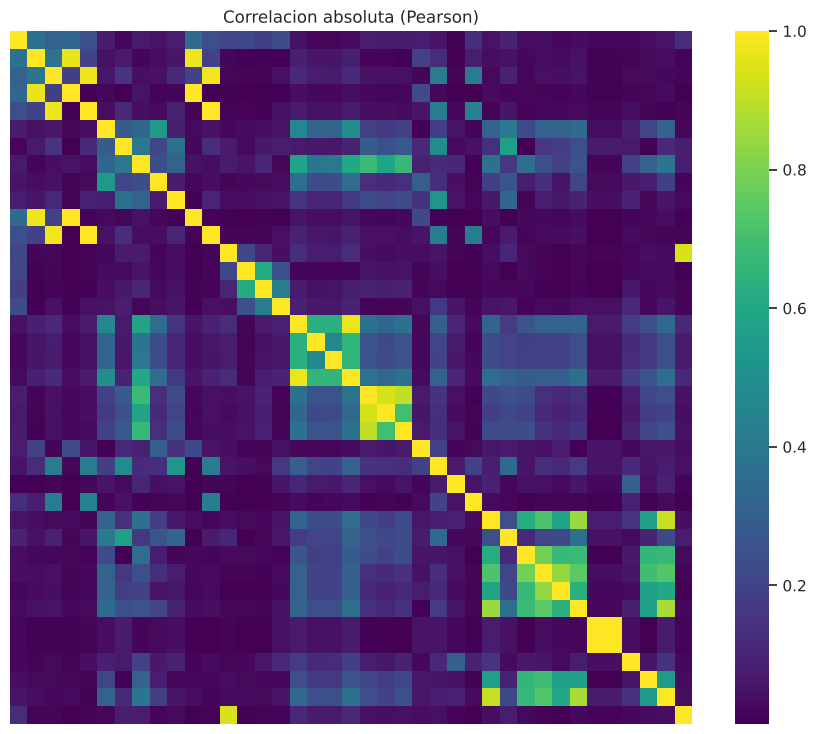

In [4]:
corr = numeric.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().sort_values(ascending=False)
print('Pares con |r| > 0.95:', int((pairs > 0.95).sum()), 'de', len(pairs))
print(pairs.head(10).round(4).to_string())
redundant = [c for c in upper.columns if (upper[c] > 0.95).any()]
print('\nVariables que el filtro de correlacion descartaria:', len(redundant))
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap='viridis', xticklabels=False, yticklabels=False)
plt.title('Correlacion absoluta (Pearson)')
plt.show()

## 4. Distribucion de variables clave por clase

Muestra estratificada por clase y `log1p`, porque las variables tienen colas muy pesadas.

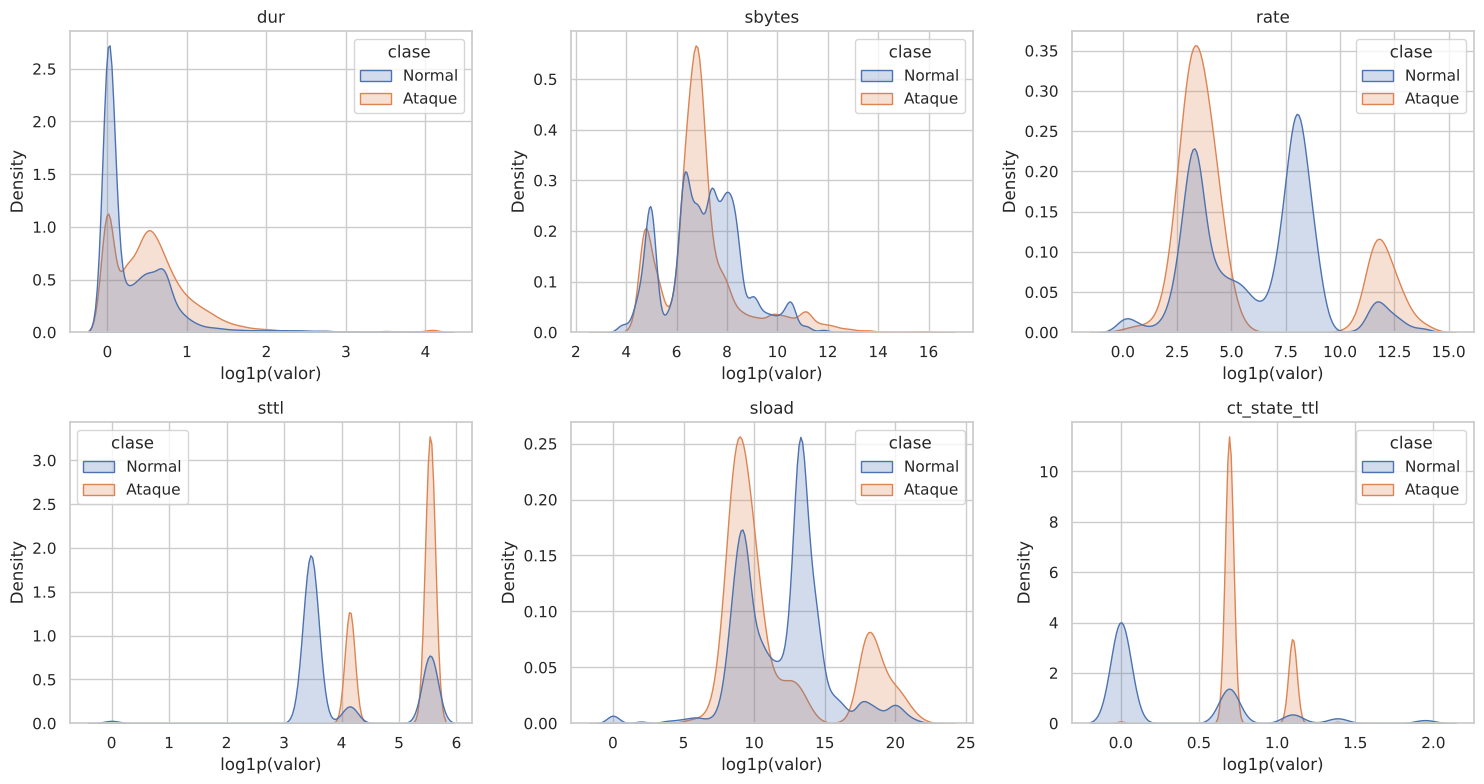

In [5]:
n = min(20000, int(y.value_counts().min()))
sample = df.groupby(config.LABEL_COLUMN, group_keys=False).sample(n=n, random_state=config.RANDOM_STATE)
sample = sample.assign(clase=sample[config.LABEL_COLUMN].map({0: 'Normal', 1: 'Ataque'}))
key_features = ['dur', 'sbytes', 'rate', 'sttl', 'sload', 'ct_state_ttl']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feature in zip(axes.ravel(), key_features):
    values = np.log1p(sample[feature].clip(lower=0))
    sns.kdeplot(data=sample.assign(v=values), x='v', hue='clase', common_norm=False, fill=True, ax=ax)
    ax.set_title(feature)
    ax.set_xlabel('log1p(valor)')
plt.tight_layout()
plt.show()

## 5. Variables categoricas

In [6]:
for column in DATASET.categorical_columns:
    table = pd.crosstab(df[column], df[config.LABEL_COLUMN], normalize='index').round(3)
    top = df[column].value_counts().head(8).index
    print(column, '- valores:', df[column].nunique())
    print(table.loc[top].rename(columns={0: 'P(normal)', 1: 'P(ataque)'}).to_string(), '\n')

proto - valores: 133
label  P(normal)  P(ataque)
proto                      
tcp        0.555      0.445
udp        0.580      0.420
arp        1.000      0.000
unas       0.000      1.000
ospf       0.328      0.672
sctp       0.000      1.000
igmp       1.000      0.000
any        0.000      1.000 

service - valores: 13
label     P(normal)  P(ataque)
service                       
-             0.618      0.382
http          0.345      0.655
dns           0.610      0.390
smtp          0.325      0.675
ftp-data      0.785      0.215
ftp           0.494      0.506
ssh           0.990      0.010
pop3          0.003      0.997 

state - valores: 11
label  P(normal)  P(ataque)
state                      
FIN        0.537      0.463
INT        0.250      0.750
CON        0.965      0.035
REQ        0.921      0.079
RST        0.857      0.143
ECO        1.000      0.000
ACC        0.500      0.500
PAR        1.000      0.000 

